# Flood-It!: retention and new-player funnel

The numbers below are the outputs of the BigQuery queries in `sql/` (run in the BigQuery sandbox,
results copied here). This notebook only turns them into tables and a chart.

- `05_retention_d1_d7.sql`: D1 / D7 retention of new players
- `06_new_user_funnel.sql`: steps reached in the first 7 days
- `06b_activation_vs_d7.sql`: D7 by "completed 5 levels within 24 hours"

Cohort: new players (`first_open`) who installed up to 2018-09-26, so day 7 is inside the data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

retention = pd.DataFrame({'new_users': [3998], 'd1_users': [790], 'd1_pct': [19.8],
                          'd7_users': [212], 'd7_pct': [5.3]})
retention

,new_users,d1_users,d1_pct,d7_users,d7_pct
0,3998,790,19.8,212,5.3


In [2]:
funnel = pd.DataFrame({
    'step': ['Installed', 'Started a level', 'Completed a level', 'Completed 5 levels'],
    'users': [3998, 3364, 2465, 926],
})
funnel['pct_of_installs'] = (funnel['users'] / funnel['users'].iloc[0] * 100).round(1)
funnel['pct_of_previous_step'] = (funnel['users'] / funnel['users'].shift() * 100).round(1)
funnel

,step,users,pct_of_installs,pct_of_previous_step
0,Installed,3998,100.0,NaN
1,Started a level,3364,84.1,84.1
2,Completed a level,2465,61.7,73.3
3,Completed 5 levels,926,23.2,37.6


The biggest drop-off is between the first and the fifth completed level: only 37.6% of players who complete
a level go on to complete five within the first week.

In [3]:
activation = pd.DataFrame({
    'completed_5_levels_within_24h': [False, True],
    'users': [3177, 821], 'd7_users': [142, 70],
})
activation['d7_pct'] = (activation['d7_users'] / activation['users'] * 100).round(1)
activation

,completed_5_levels_within_24h,users,d7_users,d7_pct
0,False,3177,142,4.5
1,True,821,70,8.5


Players who complete 5 levels on their first day return on day 7 about twice as often (8.5% vs 4.5%).
This is a **correlation**, not proof of cause: more engaged players may both progress faster and come back.
It makes "5 levels in the first session" a candidate activation metric worth testing (e.g. an easier start).

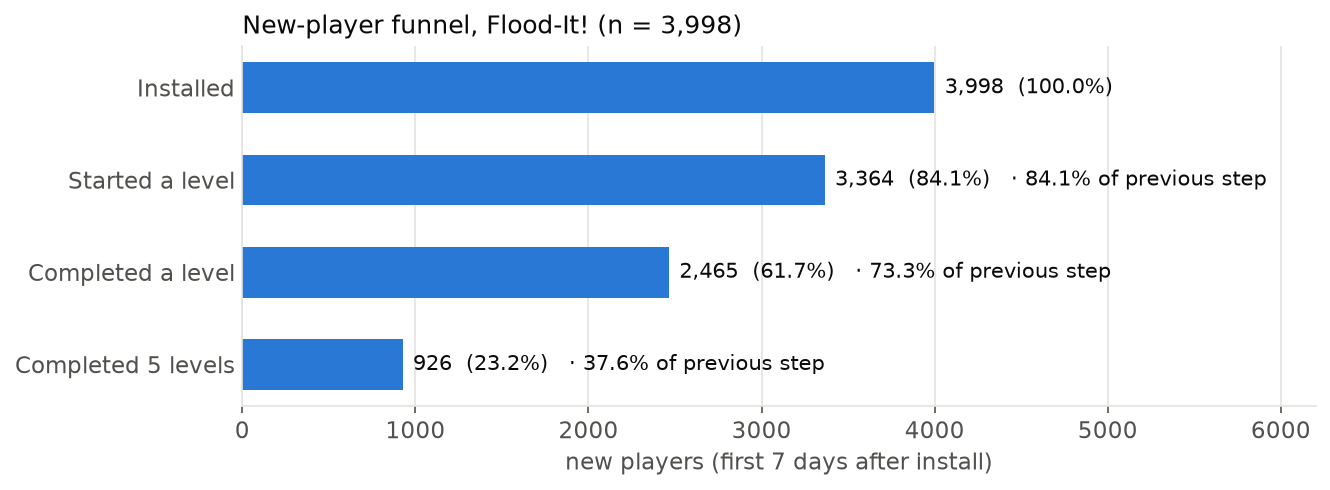

In [4]:
INK, MUTED, GRID, SERIES = '#0b0b0b', '#52514e', '#e4e3df', '#2a78d6'
plt.rcParams.update({'font.size': 11, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 150})

fig, ax = plt.subplots(figsize=(9, 3.4))
ys = range(len(funnel))[::-1]
ax.barh(list(ys), funnel['users'], color=SERIES, height=0.55)
for y, (_, r) in zip(ys, funnel.iterrows()):
    label = f"{r['users']:,}  ({r['pct_of_installs']:.1f}%)"
    if pd.notna(r['pct_of_previous_step']):
        label += f"   · {r['pct_of_previous_step']:.1f}% of previous step"
    ax.text(r['users'] + 60, y, label, va='center', color=INK, fontsize=10)
ax.set_yticks(list(ys), funnel['step'])
ax.set_xlim(0, 6200)
ax.set_xlabel('new players (first 7 days after install)')
ax.set_title('New-player funnel, Flood-It! (n = 3,998)', loc='left', color=INK, fontsize=12)
ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(axis='y', length=0)
fig.tight_layout()
fig.savefig('../figures/new_player_funnel.png', bbox_inches='tight')